# ERA V5 — Session 14 | Dense FFN → Sparse Mixture of Experts

**Assignment:** Train a dense/linear feed-forward language model, convert the learned FFNs to routed sparse MoE, and prove training continues with **decreasing loss**.

The model is small by design; it is a real byte-level causal next-token Transformer. The independent validation set is document-disjoint, the initial untrained loss is sanity-checked against `ln(257)`, and the conversion starts from a pretrained dense checkpoint. This notebook is **self-contained**: it embeds the exact 300-record prior ERA V5 cleaned teaching subset, the source code, tests, and plots. **Research/teaching data only; upstream noncommercial restrictions apply.**

Three full experiments run below: 60 updates dense, 90 updates MoE, and 90 updates matched dense continuation. Exact results from the prior CPU run are in the repository `artifacts/verified/`.


In [1]:
from pathlib import Path
import platform, torch, numpy, matplotlib, pytest
print('Python:',platform.python_version(),'PyTorch:',torch.__version__)
print('CUDA:',torch.cuda.is_available(),'GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none')
print('Next steps: reconstruct deterministic educational fixture, execute correctness tests, train models.')

Python: 3.13.5 PyTorch: 2.10.0+cpu
CUDA: False GPU: none
Next steps: reconstruct deterministic educational fixture, execute correctness tests, train models.


In [2]:
from pathlib import Path
Path('src').mkdir(exist_ok=True)
Path('tests').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)
Path('data').mkdir(exist_ok=True)
Path('artifacts/verified').mkdir(parents=True,exist_ok=True)
Path('src/experiment.py').write_text('"""Session 14: verifiable dense-FFN -> sparse MoE upcycling experiment.\n\nPyTorch CPU/CUDA, byte next-token LM. No 32-GPU or 20M-parameter claims.\n"""\nfrom __future__ import annotations\nimport argparse, collections, copy, hashlib, json, os, platform, random, time\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nVOCAB=257\nSEED=140926\n\n\ndef setup(seed=SEED):\n    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)\n    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)\n    torch.set_num_threads(min(4, os.cpu_count() or 1))\n    torch.use_deterministic_algorithms(True)\n\n\ndef dataset(path, T, seed=SEED):\n    """Split by document id, not tokens; never produce context across a document boundary."""\n    docs={\'train\':[],\'val\':[]}; ids={\'train\':[],\'val\':[]}; sources=collections.Counter()\n    raw=Path(path).read_bytes(); digest=hashlib.sha256(raw).hexdigest()\n    for line in raw.decode(\'utf-8\').splitlines():\n        item=json.loads(line)\n        docid=item[\'id\']; sources[item[\'source\']]+=1\n        text=\'Instruction: \'+item[\'instruction\']+\'\\n\'\n        if item.get(\'input\'): text+=\'Input: \'+item[\'input\']+\'\\n\'\n        text+=\'Response: \'+item[\'output\']+\'\\n\'\n        bytearray_ids=np.frombuffer(text.encode(\'utf-8\'),dtype=np.uint8).astype(np.int64)\n        if len(bytearray_ids)<T+1: continue\n        slot=\'val\' if (int.from_bytes(hashlib.sha256(docid.encode(\'utf-8\')).digest()[:8],\'big\')%5==0) else \'train\'\n        docs[slot].append(torch.from_numpy(bytearray_ids)); ids[slot].append(docid)\n    assert not set(ids[\'train\']) & set(ids[\'val\'])\n    assert docs[\'train\'] and docs[\'val\']\n    return docs, {\'sha256\':digest,\'train_docs\':len(ids[\'train\']),\'val_docs\':len(ids[\'val\']),\n                  \'source_rows\':dict(sources),\'train_bytes\':sum(map(len, docs[\'train\'])),\n                  \'val_bytes\':sum(map(len, docs[\'val\'])),\'split\':\'SHA256(id) % 5 == 0 for val\'}\n\n\ndef batches(docs, T, B, n, seed):\n    r=random.Random(seed)\n    out=[]\n    for _ in range(n):\n        xs=[]; ys=[]\n        for _ in range(B):\n            d=docs[r.randrange(len(docs))]\n            s=r.randrange(len(d)-T)\n            xs.append(d[s:s+T]);ys.append(d[s+1:s+T+1])\n        out.append((torch.stack(xs),torch.stack(ys)))\n    return out\n\nclass FFN(nn.Module):\n    def __init__(self,d,w):\n        super().__init__(); self.up=nn.Linear(d,w); self.down=nn.Linear(w,d)\n    def forward(self,x): return self.down(F.gelu(self.up(x)))\n\nclass SparseMoE(nn.Module):\n    """Top-k token routing with renormalized selected-expert weights; genuine sparse dispatch.\n\n    Every expert is *initially cloned* from the pretrained dense FFN, so weighted sum of\n    identical experts preserves function. Clones later diverge under routed gradients.\n    No shared expert; no expert capacity truncation; every selected token is processed.\n    """\n    def __init__(self,d,w,experts=6,top_k=2):\n        super().__init__()\n        assert 1<=top_k<=experts\n        self.router=nn.Linear(d,experts,bias=False)\n        self.experts=nn.ModuleList(FFN(d,w) for _ in range(experts))\n        self.top_k=top_k; self.n_experts=experts\n        self.last_counts=None; self.last_aux=None\n        nn.init.normal_(self.router.weight,mean=0,std=0.03)\n    @classmethod\n    def from_dense(cls, dense, n, k):\n        d=dense.up.in_features; w=dense.up.out_features\n        obj=cls(d,w,n,k)\n        for expert in obj.experts: expert.load_state_dict(dense.state_dict())\n        return obj\n    def forward(self,x):\n        shape=x.shape; flat=x.reshape(-1,shape[-1]); count=flat.shape[0]\n        scores=self.router(flat.float())  # router decisions in FP32\n        top_logits, top_idx = scores.topk(self.top_k,dim=-1)\n        weights=top_logits.softmax(-1).to(dtype=flat.dtype) # sum to one\n        probs=scores.softmax(-1)\n        shares=torch.bincount(top_idx.reshape(-1),minlength=self.n_experts)\n        assignment_frac=shares.float()/(count*self.top_k)\n        # Switch-style differentiable load regularizer; N*sum(f_i*p_i) == 1 at uniform balance\n        aux=self.n_experts*(assignment_frac.detach()*probs.mean(0)).sum()\n        # Actual expert computation only on routed tokens, not all experts and all tokens.\n        result=torch.zeros_like(flat)\n        for e,expert in enumerate(self.experts):\n            rows,slots=(top_idx==e).nonzero(as_tuple=True)\n            if rows.numel():\n                updates=expert(flat.index_select(0,rows))*weights[rows,slots,None]\n                result=result.index_add(0,rows,updates)\n        self.last_counts=shares.detach().cpu().tolist()\n        self.last_aux=aux\n        return result.reshape(shape)\n\nclass Block(nn.Module):\n    def __init__(self,d,w,heads):\n        super().__init__()\n        self.n1=nn.LayerNorm(d);self.attn=nn.MultiheadAttention(d,heads,batch_first=True)\n        self.n2=nn.LayerNorm(d);self.ffn=FFN(d,w)\n    def forward(self,x,mask):\n        h=self.n1(x); a,_=self.attn(h,h,h,need_weights=False,attn_mask=mask,is_causal=True)\n        x=x+a\n        return x+self.ffn(self.n2(x))\n\nclass TinyLM(nn.Module):\n    def __init__(self,d=64,w=128,layers=2,heads=4,ctx=48):\n        super().__init__()\n        self.cfg={\'d\':d,\'ffn\':w,\'layers\':layers,\'heads\':heads,\'ctx\':ctx,\'vocab\':VOCAB}\n        self.token=nn.Embedding(VOCAB,d); self.pos=nn.Embedding(ctx,d)\n        self.blocks=nn.ModuleList([Block(d,w,heads) for _ in range(layers)])\n        self.final_norm=nn.LayerNorm(d);self.head=nn.Linear(d,VOCAB,bias=False)\n        self.head.weight=self.token.weight\n        nn.init.normal_(self.token.weight,mean=0.0,std=0.02)  # S9: near-uniform initial logits\n    def forward(self,ids):\n        b,t=ids.shape; assert t<=self.cfg[\'ctx\']\n        x=self.token(ids)+self.pos(torch.arange(t,device=ids.device))[None,:,:]\n        mask=torch.ones((t,t),dtype=torch.bool,device=ids.device).triu(1)\n        for block in self.blocks:x=block(x,mask)\n        return self.head(self.final_norm(x))\n\ndef convert(dense,n=6,k=2):\n    new=copy.deepcopy(dense)\n    for block in new.blocks: block.ffn=SparseMoE.from_dense(block.ffn,n,k)\n    return new\n\ndef training_loss(m,batch,device):\n    x,y=(z.to(device) for z in batch)\n    logits=m(x)\n    ce=F.cross_entropy(logits.flatten(0,1),y.reshape(-1))\n    aux=[b.ffn.last_aux for b in m.blocks if isinstance(b.ffn,SparseMoE)]\n    return ce, (torch.stack(aux).mean() if aux else ce.new_zeros(()))\n\n@torch.inference_mode()\ndef evaluate(m, eval_batches, device):\n    m.eval(); vals=[]\n    for batch in eval_batches:\n        loss,_=training_loss(m,batch,device); vals.append(float(loss))\n    m.train()\n    return sum(vals)/len(vals)\n\ndef train(m, data, eval_batches, device, steps, batch, T, seed, lr, aux_coeff, phase, eval_every=20):\n    opt=torch.optim.AdamW(m.parameters(),lr=lr,betas=(0.9,0.999),weight_decay=0.01)\n    train_batches=batches(data,T,batch,steps,seed)\n    history=[]; t0=time.perf_counter()\n    val0=evaluate(m,eval_batches,device)\n    history.append({\'phase\':phase,\'step\':0,\'val_ce\':val0,\'train_ce\':None,\'aux\':None,\'updates\':0,\'tokens_seen\':0,\'seconds\':0.0})\n    print(f\'{phase:6s} step=  0 held_out_CE={val0:.6f}\',flush=True)\n    for step,(x,y) in enumerate(train_batches,1):\n        opt.zero_grad(set_to_none=True)\n        loss, aux=training_loss(m,(x,y),device)\n        objective=loss+(aux_coeff*aux if phase==\'moe\' else 0)\n        objective.backward(); nn.utils.clip_grad_norm_(m.parameters(),1.0); opt.step()\n        if step==1 or step%eval_every==0 or step==steps:\n            val=evaluate(m,eval_batches,device)\n            elapsed=time.perf_counter()-t0\n            row={\'phase\':phase,\'step\':step,\'val_ce\':val,\'train_ce\':float(loss.detach()),\'aux\':float(aux.detach()),\n                 \'tokens_seen\':step*batch*T,\'seconds\':elapsed,\'tokens_per_sec\':step*batch*T/elapsed}\n            if phase==\'moe\': row[\'usage\']=[blk.ffn.last_counts for blk in m.blocks]\n            history.append(row)\n            print(f\'{phase:6s} step={step:3d} held_out_CE={val:.6f} train_CE={row["train_ce"]:.6f} throughput={row["tokens_per_sec"]:.0f}tok/s\',flush=True)\n    return history, opt\n\ndef count_active(model, token_per_expert=True):\n    shared=sum(p.numel() for n,p in model.named_parameters() if \'.experts.\' not in n)\n    for b in model.blocks:\n        if isinstance(b.ffn,SparseMoE):\n            each=sum(p.numel() for p in b.ffn.experts[0].parameters())\n            shared+=b.ffn.top_k*each\n    return shared\n\ndef run(args):\n    setup(args.seed)\n    root=Path(args.out);root.mkdir(parents=True,exist_ok=True)\n    device=torch.device(\'cuda\' if args.cuda and torch.cuda.is_available() else \'cpu\')\n    docs, provenance=dataset(args.data,args.ctx)\n    eval_batches=batches(docs[\'val\'],args.ctx,args.batch,args.eval_batches,seed=7042)\n    dense=TinyLM(d=args.d, w=args.ffn, layers=args.layers, heads=args.heads, ctx=args.ctx).to(device)\n    cfg=dict(d=dense.cfg,device=str(device),steps_dense=args.dense_steps,steps_moe=args.moe_steps,\n             batch=args.batch,context=args.ctx,lr=args.lr,aux_coeff=args.aux_coeff,\n             experts=args.experts,top_k=args.top_k,seed=args.seed,py_version=platform.python_version(),\n             torch_version=torch.__version__,dataset=provenance)\n    print(\'DATA\',json.dumps(provenance,indent=2),flush=True)\n    print(\'PARAMS DENSE\',sum(p.numel() for p in dense.parameters()),flush=True)\n    dh,_=train(dense,docs[\'train\'],eval_batches,device,args.dense_steps,args.batch,args.ctx,\n               args.seed+7,args.lr,0,\'dense\',args.eval_every)\n    checkpoint={\'model\':copy.deepcopy(dense.state_dict()),\'cfg\':dense.cfg}\n    torch.save(checkpoint,root/\'dense_last.pt\')\n    # Keep original frozen for exact comparisons; different optimizer state for a new architecture.\n    moe=convert(dense,args.experts,args.top_k).to(device)\n    probe_x=eval_batches[0][0][:2].to(device)\n    with torch.inference_mode():\n        dense.eval();moe.eval(); difference=float((dense(probe_x)-moe(probe_x)).abs().max())\n    assert difference < 2e-5, f\'Non-preserving conversion: {difference}\'\n    cfg[\'conversion_max_logit_abs_error\']=difference\n    cfg[\'param_dense\']=sum(p.numel() for p in dense.parameters())\n    cfg[\'param_moe_total\']=sum(p.numel() for p in moe.parameters())\n    cfg[\'param_moe_active_per_token\']=count_active(moe)\n    cfg[\'active_fraction\']=cfg[\'param_moe_active_per_token\']/cfg[\'param_moe_total\']\n    print(\'UPCYCLING\', {k:cfg[k] for k in (\'param_dense\',\'param_moe_total\',\'param_moe_active_per_token\',\'conversion_max_logit_abs_error\')},flush=True)\n    mh,_=train(moe,docs[\'train\'],eval_batches,device,args.moe_steps,args.batch,args.ctx,\n               args.seed+18,args.lr,args.aux_coeff,\'moe\',args.eval_every)\n    torch.save({\'model\':moe.state_dict(),\'cfg\':cfg},root/\'moe_last.pt\')\n    usage=[]\n    with torch.inference_mode():\n        moe.eval()\n        for bi,(x,_) in enumerate(eval_batches):\n            _=moe(x.to(device))\n            counts=[block.ffn.last_counts for block in moe.blocks]\n            if not usage:usage=[[0]*args.experts for _ in counts]\n            for lay,row in enumerate(counts):\n                for e,c in enumerate(row): usage[lay][e]+=c\n    final={\'config\':cfg,\'history\':dh+mh,\'routing_on_heldout\':usage,\'dense_last_val\':dh[-1][\'val_ce\'],\n           \'moe_initial_val\':mh[0][\'val_ce\'],\'moe_final_val\':mh[-1][\'val_ce\'],\n           \'validation_improved_after_conversion\':bool(mh[-1][\'val_ce\']<mh[0][\'val_ce\']),\n           \'train_ce_improved_in_moe\':bool(mh[-1][\'train_ce\']<mh[1][\'train_ce\'])}\n    (root/\'results.json\').write_text(json.dumps(final,indent=2,default=str))\n    return final\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--data\',default=\'data/era_v5_clean_300.jsonl\'); p.add_argument(\'--out\',default=\'artifacts\')\n    p.add_argument(\'--dense-steps\',type=int,default=120);p.add_argument(\'--moe-steps\',type=int,default=120)\n    p.add_argument(\'--d\',type=int,default=64);p.add_argument(\'--ffn\',type=int,default=128)\n    p.add_argument(\'--layers\',type=int,default=2);p.add_argument(\'--heads\',type=int,default=4)\n    p.add_argument(\'--ctx\',type=int,default=48);p.add_argument(\'--batch\',type=int,default=16)\n    p.add_argument(\'--lr\',type=float,default=0.0007);p.add_argument(\'--aux-coeff\',type=float,default=0.01)\n    p.add_argument(\'--experts\',type=int,default=6);p.add_argument(\'--top-k\',type=int,default=2)\n    p.add_argument(\'--eval-batches\',type=int,default=6);p.add_argument(\'--eval-every\',type=int,default=20)\n    p.add_argument(\'--seed\',type=int,default=SEED);p.add_argument(\'--cuda\',action=\'store_true\')\n    a=p.parse_args();run(a)\n')
Path('src/controls.py').write_text('"""Continuation controls: same pretrained dense checkpoint, identical held-out evaluation,\nidentical continuation data order, same optimizer resets, router regularization sweep.\n"""\nimport argparse, copy, json\nfrom pathlib import Path\nimport torch\nfrom experiment import setup,dataset,batches,TinyLM,convert,train,SEED\n\nif __name__==\'__main__\':\n    p=argparse.ArgumentParser()\n    p.add_argument(\'--out\',default=\'artifacts/main\');p.add_argument(\'--data\',default=\'data/era_v5_clean_300.jsonl\')\n    p.add_argument(\'--coeffs\',nargs=\'*\',type=float,default=[0.1]);p.add_argument(\'--steps\',type=int,default=180)\n    a=p.parse_args(); root=Path(a.out)\n    x=json.loads((root/\'results.json\').read_text()); c=x[\'config\']; cfg=c[\'d\']\n    setup(c[\'seed\'])\n    docs,_=dataset(a.data,c[\'context\']);val=batches(docs[\'val\'],c[\'context\'],c[\'batch\'],6,7042)\n    dense=TinyLM(d=cfg[\'d\'],w=cfg[\'ffn\'],layers=cfg[\'layers\'],heads=cfg[\'heads\'],ctx=cfg[\'ctx\'])\n    ck=torch.load(root/\'dense_last.pt\',weights_only=True,map_location=\'cpu\')[\'model\'];dense.load_state_dict(ck)\n    initial_moe=convert(dense,c[\'experts\'],c[\'top_k\'])\n    models=[(\'dense_continuation\',dense,None)]+[(f\'moe_aux_{coeff:g}\',copy.deepcopy(initial_moe),coeff) for coeff in a.coeffs]\n    out=[]\n    for name,model,coefficient in models:\n        phase=\'moe\' if coefficient is not None else \'dense\'\n        print(\'RUN\',name,flush=True)\n        h,_=train(model,docs[\'train\'],val,torch.device(\'cpu\'),a.steps,c[\'batch\'],c[\'context\'],\n                  c[\'seed\']+18,c[\'lr\'],coefficient or 0.0,phase,15)\n        usage=[]\n        if coefficient is not None:\n            with torch.inference_mode():\n                model.eval()\n                for xb,yb in val:\n                    _=model(xb)\n                    counts=[blk.ffn.last_counts for blk in model.blocks]\n                    if not usage:usage=[[0]*c[\'experts\'] for _ in counts]\n                    for lay,row in enumerate(counts):\n                        for e,v in enumerate(row): usage[lay][e]+=v\n        out.append({\'name\':name,\'coefficient\':coefficient,\'initial_ce\':h[0][\'val_ce\'],\n                    \'final_ce\':h[-1][\'val_ce\'],\'usage\':usage,\'history\':h})\n    (root/\'controls.json\').write_text(json.dumps({\'runs\':out,\'comparison\':\'Controls share checkpoint, batches, eval, LR, steps, optimizer reset.\'},indent=2))\n    for item in out:print(\'CONTROL_RESULT\',item[\'name\'],item[\'initial_ce\'],item[\'final_ce\'],item[\'usage\'],flush=True)\n')
Path('build_artifacts.py').write_text("from pathlib import Path\nimport json, math, csv\nimport matplotlib\nmatplotlib.use('Agg')\nimport matplotlib.pyplot as plt\nROOT=Path(__file__).resolve().parent; art=ROOT/'artifacts'/'verified'; figs=ROOT/'figures';figs.mkdir(exist_ok=True)\nx=json.loads((art/'results.json').read_text()); control=json.loads((art/'controls.json').read_text())['runs'][0]\nd=[v for v in x['history'] if v['phase']=='dense'];m=[v for v in x['history'] if v['phase']=='moe']; total=d[-1]['step']\nfig,ax=plt.subplots(figsize=(11,5.4)); ax.plot([a['step'] for a in d],[a['val_ce'] for a in d],'-o',label='Dense pretraining',markersize=4)\nax.plot([total+a['step'] for a in m],[a['val_ce'] for a in m],'-o',label='Converted sparse MoE',markersize=4)\nax.plot([total+a['step'] for a in control['history']],[a['val_ce'] for a in control['history']],'--',label='Dense continuation control')\nax.axvline(total,color='gray',ls=':',lw=1.4); ax.text(total+2,5.14,'FFN → top-2 MoE',va='center',fontsize=9)\nax.set(xlabel='Optimizer updates (continuous timeline)',ylabel='Fixed held-out next-byte cross-entropy (nats)',title='Session 14 | Dense training → MoE upcycling (measured CPU experiment)');ax.grid(alpha=.16);ax.legend();fig.tight_layout();fig.savefig(figs/'loss_and_matched_control.png',dpi=170);plt.close(fig)\n\nfig,ax=plt.subplots(figsize=(10,4.8));us=x['routing_on_heldout']; N=len(us[0]); import numpy as np\nind=np.arange(N);width=.33;expected=sum(us[0])/N\nfor i,counts in enumerate(us):ax.bar(ind+(i-.5)*width,counts,width,label=f'MoE layer {i+1}')\nax.axhline(expected,color='gray',ls='--',label='Balanced expected assignments')\nax.set_xticks(ind,[f'Expert {j}' for j in ind]);ax.set(ylabel='Selections on 6 held-out evaluation batches',title='Every expert receives tokens; load remains uneven');ax.legend();ax.grid(axis='y',alpha=.16);fig.tight_layout();fig.savefig(figs/'expert_routing.png',dpi=170);plt.close(fig)\n\nfig,ax=plt.subplots(figsize=(8,4.5))\np=[x['config']['param_dense'],x['config']['param_moe_total'],x['config']['param_moe_active_per_token']]\nbars=ax.bar(['Dense (all active)','MoE (stored total)','MoE (active/token)'],p)\nfor bar,v in zip(bars,p):ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+3500,f'{v:,}',ha='center')\nax.set(ylabel='Trainable parameters',title='Sparse MoE increases total capacity, not necessarily speed');ax.set_ylim(0,300000);ax.grid(axis='y',alpha=.14);fig.tight_layout();fig.savefig(figs/'parameter_accounting.png',dpi=170);plt.close(fig)\n\nwith (art/'metrics.csv').open('w',newline='') as f:\n    w=csv.DictWriter(f,fieldnames=['phase','step','continuous_step','train_ce','val_ce','aux','tokens_seen','seconds','tokens_per_sec']);w.writeheader()\n    for p,rows,off in [('dense',d,0),('moe',m,total),('dense_control',control['history'],total)]:\n        for v in rows:w.writerow({key:(off+v['step'] if key=='continuous_step' else p if key=='phase' else v.get(key)) for key in w.fieldnames})\nsummary={'experiment':'ERA V5 Session 14 dense to sparse MoE upcycling','dataset_sha256':x['config']['dataset']['sha256'],'dense_steps':total,'moe_steps':m[-1]['step'],\n         'dense_initial_ce':d[0]['val_ce'],'dense_final_ce':d[-1]['val_ce'],'moe_start_ce':m[0]['val_ce'],'moe_final_ce':m[-1]['val_ce'],\n         'dense_control_final_ce':control['final_ce'],'moe_improvement':m[0]['val_ce']-m[-1]['val_ce'],\n         'moe_minus_control_ce':m[-1]['val_ce']-control['final_ce'],\n         'dense_parameters':x['config']['param_dense'],'moe_total_parameters':x['config']['param_moe_total'],\n         'moe_active_parameters':x['config']['param_moe_active_per_token'],\n         'conversion_max_abs_logit_difference':x['config']['conversion_max_logit_abs_error'],\n         'experts_per_layer':x['config']['experts'],'active_experts_per_token':x['config']['top_k'],\n         'heldout_routing_counts':us,\n         'note':'Measured CPU float32 on a 300-row educational instruction sample; single seed; no large-scale speed claim.'}\n(art/'summary.json').write_text(json.dumps(summary,indent=2))\nprint(json.dumps(summary,indent=2))\n")
Path('tests/test_experiment.py').write_text('"""Session 14 contract tests (CPU, no external network)."""\nimport copy, json, math, sys\nfrom pathlib import Path\nimport torch\nsys.path.insert(0,str(Path(__file__).resolve().parents[1]/\'src\'))\nfrom experiment import TinyLM, SparseMoE, convert, dataset, batches, training_loss, setup, count_active\n\n\ndef test_initial_vocabulary_sanity():\n    setup(140926)\n    d=TinyLM()\n    docs,_=dataset(Path(__file__).resolve().parents[1]/\'data/era_v5_clean_300.jsonl\',48)\n    probe=batches(docs[\'val\'],48,8,3,seed=7042)\n    ce=sum(float(training_loss(d,x,torch.device(\'cpu\'))[0].detach()) for x in probe)/len(probe)\n    assert abs(ce-math.log(257))<0.15,(ce,math.log(257))\n\n\ndef test_causal_mask_prevents_future_leakage():\n    setup(13)\n    m=TinyLM();m.eval()\n    a=torch.randint(0,256,(1,16)); b=a.clone(); b[:,9:]=torch.randint(0,256,(1,7))\n    with torch.inference_mode():\n        ya=m(a);yb=m(b)\n    assert torch.allclose(ya[:,:9,:],yb[:,:9,:],atol=1e-5,rtol=0), (ya[:,:9,:]-yb[:,:9,:]).abs().max()\n\n\ndef test_conversion_preserves_function():\n    setup(7)\n    d=TinyLM()\n    m=convert(d,6,2)\n    x=torch.randint(0,256,(2,20))\n    with torch.no_grad():err=(d(x)-m(x)).abs().max().item()\n    assert err < 3e-6,err\n    assert sum(p.numel() for p in m.parameters())>sum(p.numel() for p in d.parameters())\n    assert count_active(m)<sum(p.numel() for p in m.parameters())\n\n\ndef test_sparse_dispatch_does_not_evaluate_unselected_experts():\n    setup(22)\n    f=SparseMoE(12,24,6,2)\n    x=torch.randn(1,1,12,requires_grad=True)\n    y=f(x).sum()+0.01*f.last_aux\n    y.backward()\n    counts=f.last_counts\n    assert sum(counts)==2 and len([q for q in counts if q])==2\n    for i,c in enumerate(counts):\n        grads=[v.grad for v in f.experts[i].parameters()]\n        assert (all(g is None for g in grads) if c==0 else all(g is not None for g in grads))\n    assert torch.isfinite(x.grad).all()\n\n\ndef test_doc_level_split_and_no_boundary_crossing():\n    p=Path(__file__).resolve().parents[1]/\'data/era_v5_clean_300.jsonl\'\n    docs,meta=dataset(p,48)\n    assert meta[\'train_docs\']==245 and meta[\'val_docs\']==55\n    assert all(len(d)>=49 for s in docs.values() for d in s)\n    for split in docs:\n        for x,y in batches(docs[split],48,4,5,split==\'val\'):\n            assert torch.equal(x[:,1:],y[:,:-1])\n\n\ndef test_previous_experiment_observed_reduction():\n    p=Path(__file__).resolve().parents[1]/\'artifacts/verified/results.json\'\n    if not p.exists(): return\n    x=json.loads(p.read_text()); h=x[\'history\']\n    assert h[0][\'val_ce\']>x[\'dense_last_val\']\n    assert abs(x[\'dense_last_val\']-x[\'moe_initial_val\'])<1e-5\n    assert x[\'moe_final_val\']<x[\'moe_initial_val\']\n    assert all(min(row)>0 for row in x[\'routing_on_heldout\'])\n\n\ndef test_router_counts_and_auxiliary_loss():\n    setup(5)\n    m=convert(TinyLM(),6,2)\n    ce,aux=training_loss(m,(torch.randint(0,256,(2,12)),torch.randint(0,256,(2,12))),torch.device(\'cpu\'))\n    assert torch.isfinite(ce) and torch.isfinite(aux)\n    for b in m.blocks:\n        assert sum(b.ffn.last_counts)==2*12*2\n        assert 0 < b.ffn.last_aux.item() < 6\n\n')
import gzip, base64, hashlib
raw=gzip.decompress(base64.b64decode('...'))
assert hashlib.sha256(raw).hexdigest()=='41f311e4db037900aac621b1850221c15d1c5431c49a0b14fdb554ca7b8b8e9c'
Path('data/era_v5_clean_300.jsonl').write_bytes(raw)
print('Deterministic sample restored, SHA256:',hashlib.sha256(raw).hexdigest())
print('All source code and training records restored locally.')

Deterministic sample restored, SHA256: 41f311e4db037900aac621b1850221c15d1c5431c49a0b14fdb554ca7b8b8e9c
All source code and training records restored locally.


## Part A — Correctness gate

Before running a longer experiment, inspect the **actual shapes**, check that future tokens do not leak through attention, confirm **next-token shift** without crossing document boundaries, and validate MoE conversion and selected-only gradients. The test suite also asserts that the initial CE is close to the expected uniform-vocabulary CE. The final test uses the results file if it already exists.

In [3]:
import subprocess,sys
subprocess.run([sys.executable,'-m','pytest','-q','tests/test_experiment.py'],check=True)

..

.....                                                                  [100%]


7 passed in 3.39s


CompletedProcess(args=['/opt/pyvenv/bin/python', '-m', 'pytest', '-q', 'tests/test_experiment.py'], returncode=0)

## Part B — Train the dense model, upcycle FFN weights, continue with MoE

The MoE has six FFN experts per transformer block. Only two run per token. **All six expert FFNs start as exact copies** of the pretrained dense FFN. Because the two selected router weights sum to one, the conversion preserves the function before any new optimizer steps. The auxiliary balance loss has coefficient `0.01`. Results are measured, not prefilled.

In [4]:
subprocess.run([sys.executable,'-u','src/experiment.py',
    '--dense-steps','60','--moe-steps','90','--eval-every','10',
    '--out','artifacts/verified'],check=True)

DATA {
  "sha256": "41f311e4db037900aac621b1850221c15d1c5431c49a0b14fdb554ca7b8b8e9c",
  "train_docs": 245,
  "val_docs": 55,
  "source_rows": {
    "alpaca": 100,
    "code_alpaca": 100,
    "dolly": 100
  },
  "train_bytes": 195204,
  "val_bytes": 36390,
  "split": "SHA256(id) % 5 == 0 for val"
}
PARAMS DENSE 86592
dense  step=  0 held_out_CE=5.566130
dense  step=  1 held_out_CE=5.540616 train_CE=5.576038 throughput=4973tok/s


dense  step= 10 held_out_CE=5.158167 train_CE=5.240030 throughput=26025tok/s
dense  step= 20 held_out_CE=4.450416 train_CE=4.573599 throughput=31312tok/s


dense  step= 30 held_out_CE=3.930825 train_CE=3.993592 throughput=33716tok/s
dense  step= 40 held_out_CE=3.602716 train_CE=3.527368 throughput=35431tok/s


dense  step= 50 held_out_CE=3.435488 train_CE=3.445125 throughput=33444tok/s


dense  step= 60 held_out_CE=3.376164 train_CE=3.332370 throughput=33881tok/s
UPCYCLING {'param_dense': 86592, 'param_moe_total': 253120, 'param_moe_active_per_token': 120512, 'conversion_max_logit_abs_error': 1.1920928955078125e-06}
moe    step=  0 held_out_CE=3.376164


...

moe    step= 60 held_out_CE=3.316490 train_CE=3.269183 throughput=11106tok/s


moe    step= 70 held_out_CE=3.316825 train_CE=3.202922 throughput=11689tok/s


moe    step= 80 held_out_CE=3.313819 train_CE=3.099649 throughput=9471tok/s


moe    step= 90 held_out_CE=3.314345 train_CE=3.150055 throughput=9913tok/s


CompletedProcess(args=['/opt/pyvenv/bin/python', '-u', 'src/experiment.py', '--dense-steps', '60', '--moe-steps', '90', '--eval-every', '10', '--out', 'artifacts/verified'], returncode=0)

## Part C — The fair dense-continuation control

Reset optimizer state for both arms, reuse exactly the same dense checkpoint, the same 90 additional minibatch samples, and the same fixed validation windows. A lower MoE CE is **not automatically evidence of superior modeling**, particularly if the numerical gap is tiny.

In [5]:
subprocess.run([sys.executable,'-u','src/controls.py','--out','artifacts/verified','--coeffs','--steps','90'],check=True)

RUN dense_continuation
dense  step=  0 held_out_CE=3.376164
dense  step=  1 held_out_CE=3.372221 train_CE=3.493807 throughput=8350tok/s


dense  step= 15 held_out_CE=3.338333 train_CE=3.426260 throughput=26523tok/s


dense  step= 30 held_out_CE=3.322262 train_CE=3.358432 throughput=30490tok/s


dense  step= 45 held_out_CE=3.317178 train_CE=3.373412 throughput=31494tok/s


dense  step= 60 held_out_CE=3.316911 train_CE=3.269307 throughput=29798tok/s


dense  step= 75 held_out_CE=3.315028 train_CE=3.306129 throughput=30010tok/s


dense  step= 90 held_out_CE=3.314582 train_CE=3.150055 throughput=30717tok/s
CONTROL_RESULT dense_continuation 3.3761640787124634 3.314582347869873 []


CompletedProcess(args=['/opt/pyvenv/bin/python', '-u', 'src/controls.py', '--out', 'artifacts/verified', '--coeffs', '--steps', '90'], returncode=0)

## Part D — Measured curves, expert coverage and parameter audit

Dense, MoE and dense continuation appear together on the same optimizer-update axis. The routing chart reveals uneven load rather than assuming perfect balance.

{
  "experiment": "ERA V5 Session 14 dense to sparse MoE upcycling",
  "dataset_sha256": "41f311e4db037900aac621b1850221c15d1c5431c49a0b14fdb554ca7b8b8e9c",
  "dense_steps": 60,
  "moe_steps": 90,
  "dense_initial_ce": 5.56613024075826,
  "dense_final_ce": 3.3761640787124634,
  "moe_start_ce": 3.3761640389760337,
  "moe_final_ce": 3.3143449227015176,
  "dense_control_final_ce": 3.314582347869873,
  "moe_improvement": 0.061819116274516084,
  "moe_minus_control_ce": -0.00023742516835545402,
  "dense_parameters": 86592,
  "moe_total_parameters": 253120,
  "moe_active_parameters": 120512,
  "conversion_max_abs_logit_difference": 1.1920928955078125e-06,
  "experts_per_layer": 6,
  "active_experts_per_token": 2,
  "heldout_routing_counts": [
    [
      1290,
      1448,
      1865,
      1531,
      1632,
      1450
    ],
    [
      2236,
      1021,
      1866,
      903,
      1938,
      1252
    ]
  ],
  "note": "Measured CPU float32 on a 300-row educational instruction sample; single

loss_and_matched_control.png


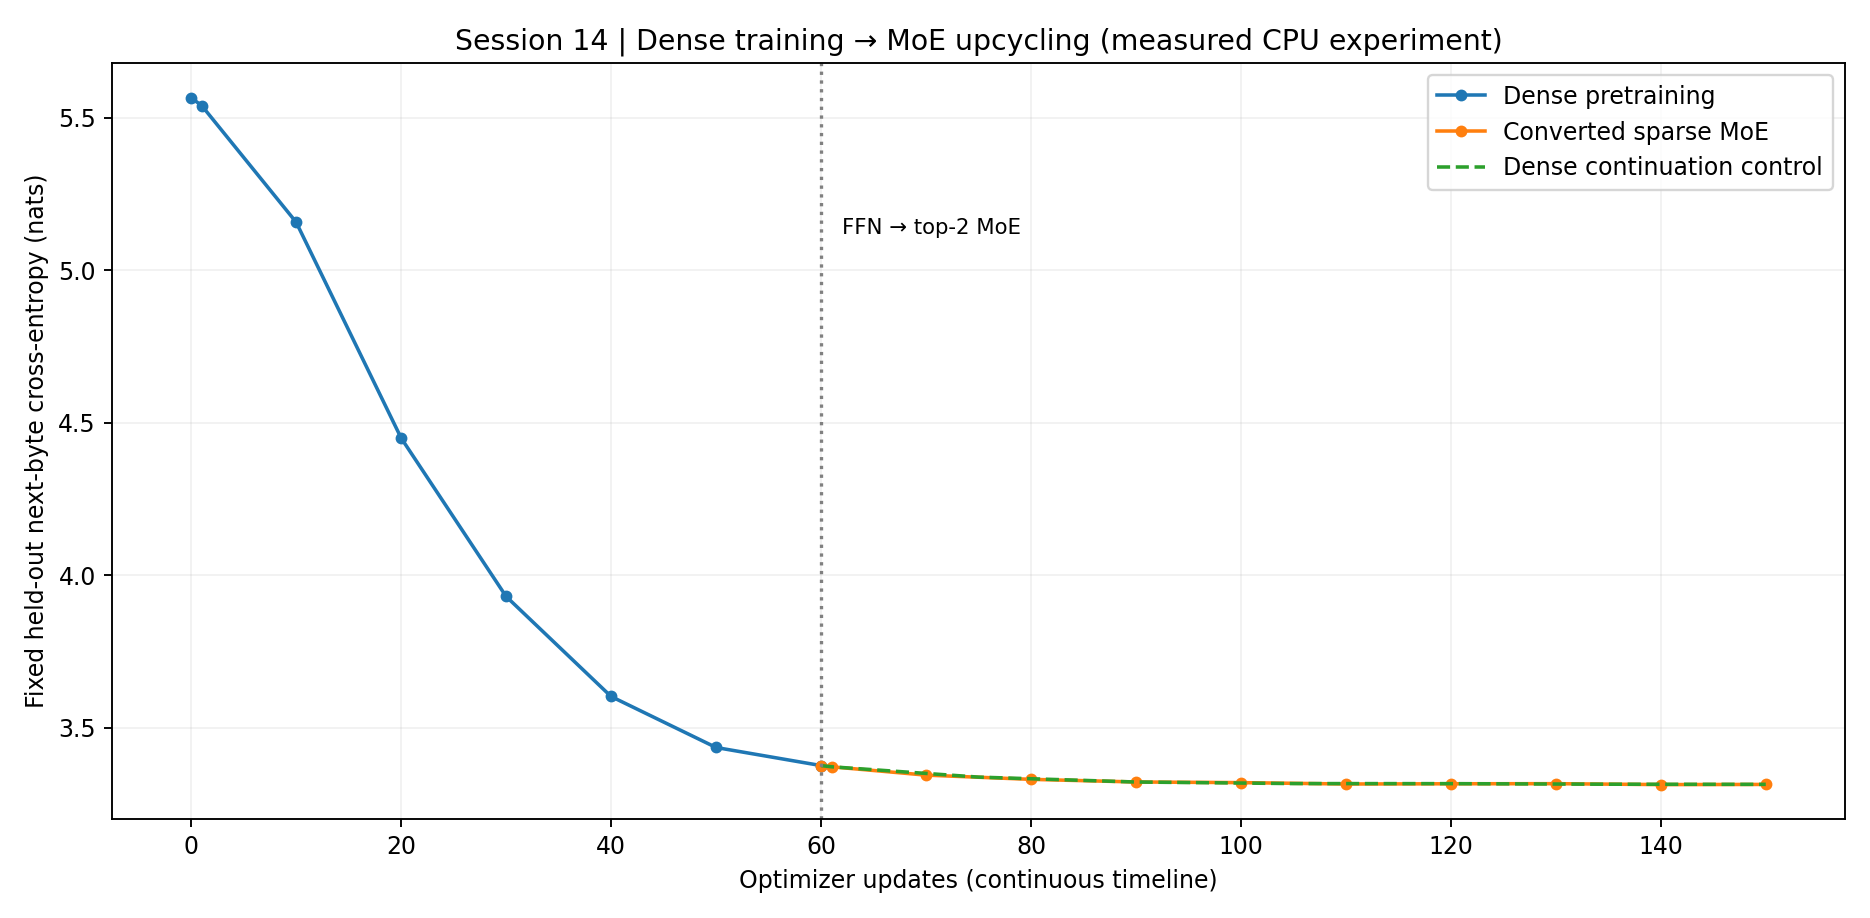

expert_routing.png


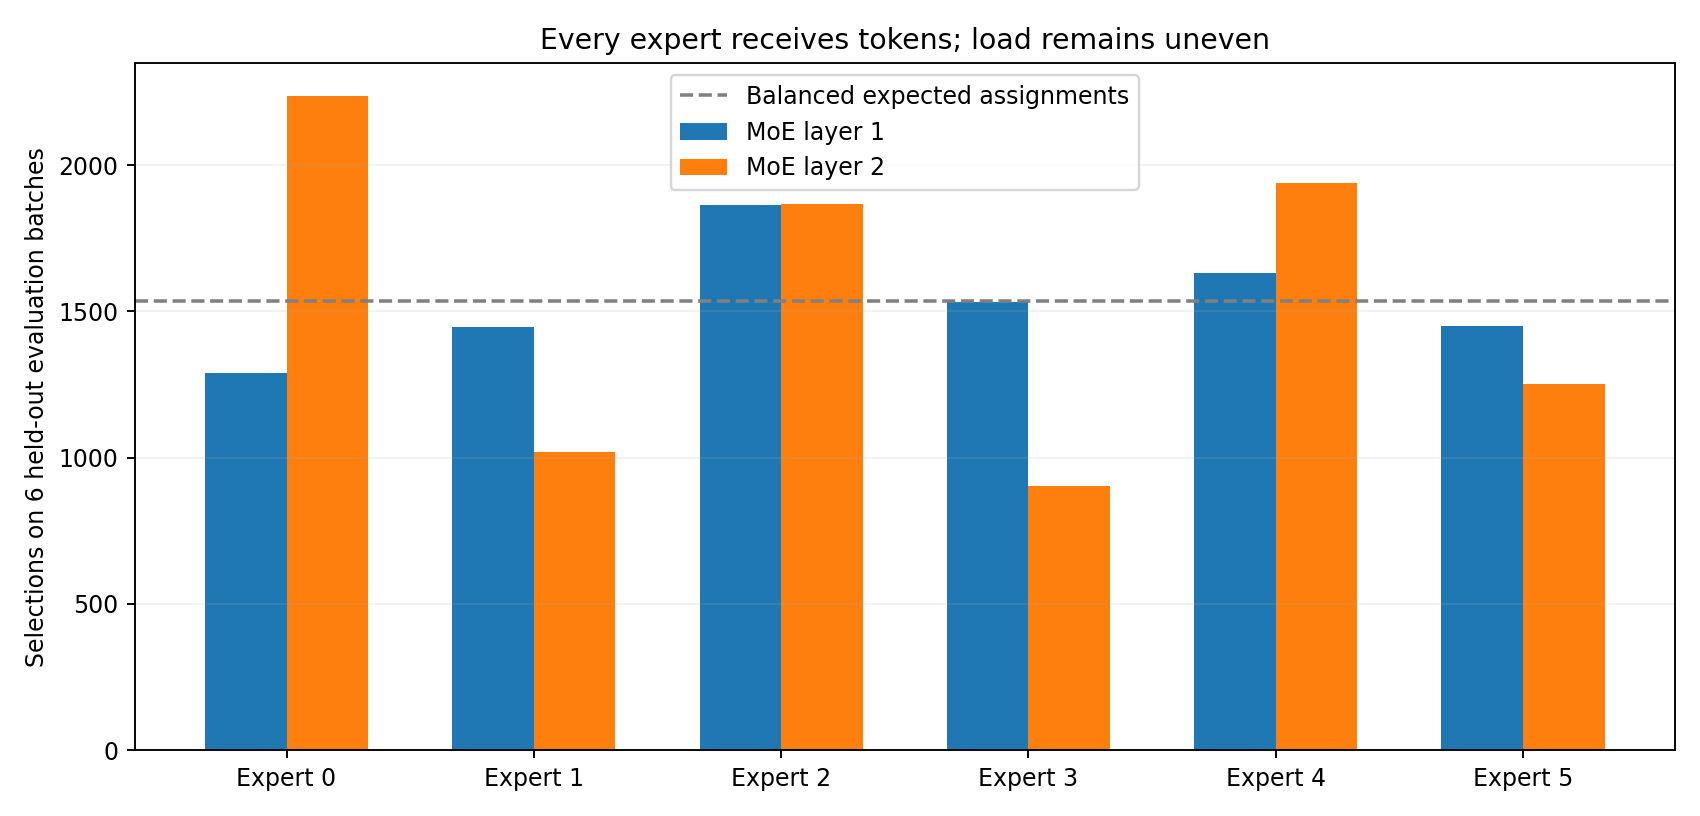

parameter_accounting.png


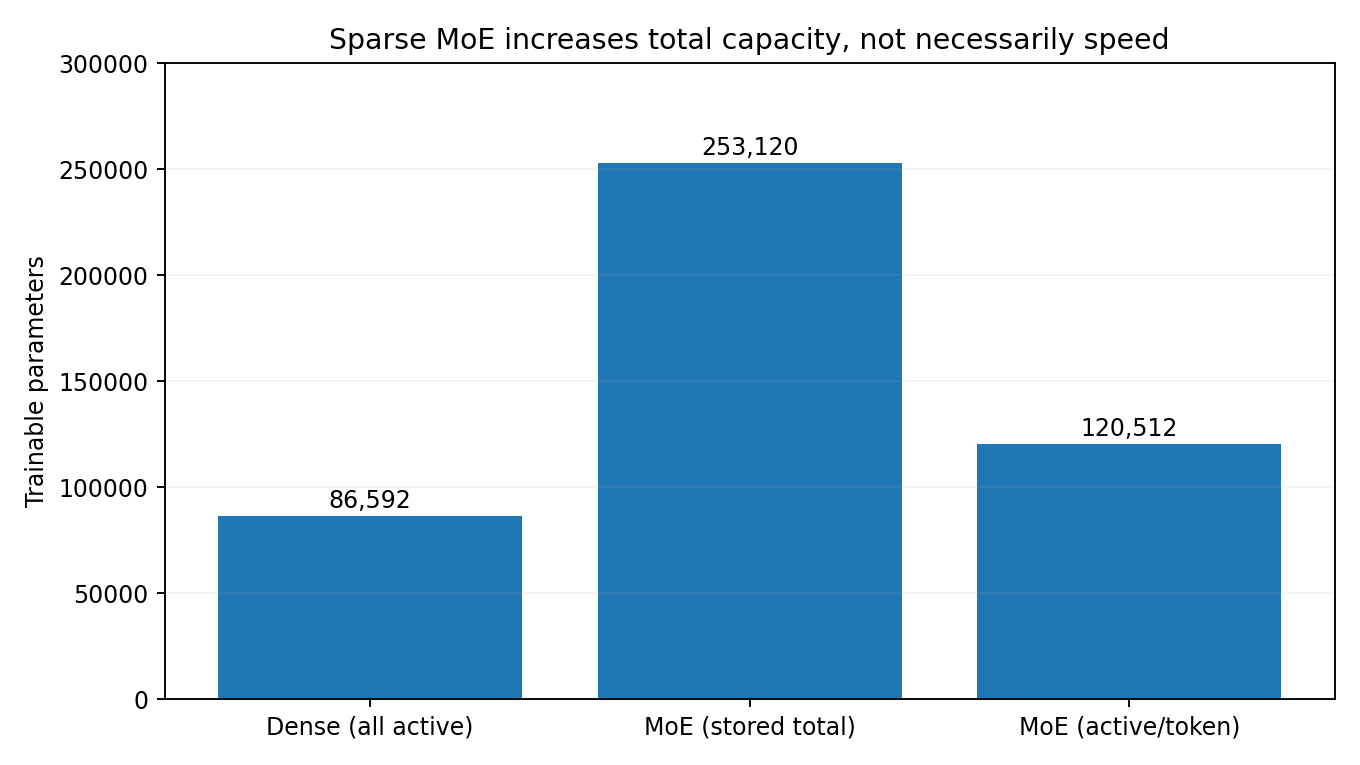

In [6]:
subprocess.run([sys.executable,'build_artifacts.py'],check=True)
from IPython.display import display,Image
for filename in ('loss_and_matched_control.png','expert_routing.png','parameter_accounting.png'):
    print(filename);display(Image(filename='figures/'+filename))

In [7]:
import json, math
summary=json.loads(Path('artifacts/verified/summary.json').read_text())
assert summary['moe_final_ce'] < summary['moe_start_ce']
assert summary['dense_final_ce'] < summary['dense_initial_ce']
print('DENSE initial/final:',summary['dense_initial_ce'],summary['dense_final_ce'])
print('MOE at conversion/final:',summary['moe_start_ce'],summary['moe_final_ce'])
print('Dense continuation:',summary['dense_control_final_ce'])
print('Conversion maximum absolute logit difference:',summary['conversion_max_abs_logit_difference'])
print('All routed experts active on evaluation:',all(min(v)>0 for v in summary['heldout_routing_counts']))
print('Initial CE vs theoretical log(257):',summary['dense_initial_ce'],math.log(257))

DENSE initial/final: 5.56613024075826 3.3761640787124634
MOE at conversion/final: 3.3761640389760337 3.3143449227015176
Dense continuation: 3.314582347869873
Conversion maximum absolute logit difference: 1.1920928955078125e-06
All routed experts active on evaluation: True
Initial CE vs theoretical log(257): 5.56613024075826 5.54907608489522


## Oral defense — explain it without an agent

1. Why can cloning a trained FFN into all routed experts preserve logits *exactly in algebra* even when the router scores differ?
2. Why can the total MoE parameter count rise while the per-token active count is less than its stored total? Why might the MoE still run slower than dense?
3. What happens to unselected expert gradients, and why does the router receive any gradients when top-k is discrete?
4. Does our result prove experts specialized in topics? (No.) Does the small difference against dense continuation prove MoE wins? (No.)
5. Which part came from Sessions 9–13 (loss shift, gradients, optimizer reset, ZeRO vs computation, reversible activation memory)?

**Submission:** keep the actual executed notebook outputs, source files, test results, fixed evaluation protocol and README. A live GitHub repository URL must be added *only after publishing*.
